# 09 – Kontext-Ablation: Woher kommt der Vorsprung des BiLSTM?

> **Ergänzende Analyse (Oktober 2026).**

**Ausgangslage:** Das BiLSTM (Notebook 08) erreicht RMSE 13.33, der Random Forest (Notebook 03) 20.72.  
Die beiden Modelle unterscheiden sich aber in **zwei** Dingen gleichzeitig:

| | Random Forest (03) | BiLSTM (08) |
|---|---|---|
| Modellklasse | Entscheidungsbäume | rekurrentes Netz + Attention |
| Zeitkontext pro Vorhersage | letzter Zyklus + Rolling-Fenster 5 | letzte 50 Zyklen |

**Frage:** Wie viel des Abstands verschwindet, wenn der Random Forest denselben 50-Zyklen-Kontext bekommt, verdichtet als  
Mittelwert, Standardabweichung und Steigung (Trend) über das Fenster?

**Vorgehen:**
1. Feature-Varianten aus den Rohdaten bauen: Fenster 5 / 30 / 50, optional Steigung und `time_in_cycles` (Alter der Engine; ist zum Vorhersagezeitpunkt bekannt).
2. Varianten per **GroupKFold-CV auf den Trainingsdaten** vergleichen. Die Auswahl erfolgt nur hierüber.
3. Erst danach alle Varianten einmal auf dem Test-Set auswerten (3 Seeds, um die Streuung des RF zu zeigen).

Alle Varianten nutzen den RF mit den Default-Parametern aus `src/config.py` (250 Bäume, ohne Tuning).  
Wie in Notebook 03 entfallen die ersten 4 Zyklen jeder Engine, damit die Trainingsmenge in allen Varianten gleich ist.

In [1]:
import sys
sys.path.append('..')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_score

from src.config import RAW_DIR, REPORTS, FINAL_SENSORS, RUL_CAP, RF_PARAMS
from src.evaluation.metrics import evaluate_all
from src.evaluation.results import load_results

sns.set_theme(style='whitegrid')
COLS = ['unit_number', 'time_in_cycles'] + [f'os_{i}' for i in range(1, 4)] + [f'sensor_{i}' for i in range(1, 22)]

def load_raw(name: str) -> pd.DataFrame:
    return pd.read_csv(RAW_DIR / f'{name}_FD003.txt', sep=r'\s+', header=None, names=COLS)

train_raw = load_raw('train')
test_raw  = load_raw('test')
y_test    = pd.read_csv(RAW_DIR / 'RUL_FD003.txt', sep=r'\s+', header=None).iloc[:, 0].values.astype(float)

max_cyc = train_raw.groupby('unit_number')['time_in_cycles'].transform('max')
y_train = np.minimum(max_cyc - train_raw['time_in_cycles'], RUL_CAP).values
groups  = train_raw['unit_number'].values
mask    = (train_raw['time_in_cycles'] > 4).values          # wie Notebook 03: erste 4 Zyklen entfallen
print(f'Train: {mask.sum()} Zeilen aus {len(np.unique(groups))} Engines | Test: {len(y_test)} Engines')

Train: 24320 Zeilen aus 100 Engines | Test: 100 Engines


## 1. Kontext-Features

Für jedes Fenster `w` und jeden der 12 Sensoren pro Zyklus:
- `m{w}`: gleitender Mittelwert über die letzten `w` Zyklen
- `sd{w}`: gleitende Standardabweichung
- `sl{w}` (optional): Steigung einer linearen Regression über das Fenster, also der Degradationstrend

Am Anfang jeder Engine wird mit den bisher verfügbaren Zyklen gerechnet (`min_periods`). So geht keine Zeile verloren,  
auch nicht bei Fenster 50. Alle Statistiken nutzen nur vergangene Zyklen, es gibt keinen Blick in die Zukunft.

In [2]:
S = FINAL_SENSORS

def context_features(df: pd.DataFrame, w: int, slope: bool) -> pd.DataFrame:
    g   = df.groupby('unit_number')
    out = df[['unit_number', 'time_in_cycles'] + S].copy()
    t   = g.cumcount().astype(float)                      # Zyklusindex innerhalb der Engine
    roll = lambda s, fn, mp: s.groupby(df['unit_number']).transform(lambda v: getattr(v.rolling(w, min_periods=mp), fn)())
    if slope:
        m_t = roll(t, 'mean', 1)
        v_t = t.groupby(df['unit_number']).transform(lambda v: v.rolling(w, min_periods=2).var(ddof=0))
    for s in S:
        out[f'{s}_m{w}']  = roll(df[s], 'mean', 1)
        out[f'{s}_sd{w}'] = roll(df[s], 'std', 2).fillna(0)
        if slope:   # Steigung = Cov(x, t) / Var(t) im Fenster
            m_xt = roll(df[s] * t, 'mean', 1)
            out[f'{s}_sl{w}'] = ((m_xt - out[f'{s}_m{w}'] * m_t) / v_t).replace([np.inf, -np.inf], np.nan).fillna(0)
    return out

VARIANTS = [   # (Name, Fenster, Steigung, time_in_cycles)
    ('w5 (wie Notebook 03)',          5, False, False),
    ('w5 + time_in_cycles',           5, False, True),
    ('w30',                          30, False, False),
    ('w30 + Steigung',               30, True,  False),
    ('w50 + Steigung',               50, True,  False),
    ('w50 + Steigung + time_in_cycles', 50, True, True),
]

features = {}
for name, w, sl, tm in VARIANTS:
    if (w, sl) not in features:
        F_tr = context_features(train_raw, w, sl)
        F_te = context_features(test_raw, w, sl).groupby('unit_number').tail(1)   # letzter Zyklus je Test-Engine
        features[(w, sl)] = (F_tr, F_te)

def feature_cols(F: pd.DataFrame, with_time: bool) -> list[str]:
    cols = [c for c in F.columns if c not in ('unit_number', 'time_in_cycles')]
    return cols + (['time_in_cycles'] if with_time else [])

print({name: len(feature_cols(features[(w, sl)][0], tm)) for name, w, sl, tm in VARIANTS})

{'w5 (wie Notebook 03)': 36, 'w5 + time_in_cycles': 37, 'w30': 36, 'w30 + Steigung': 48, 'w50 + Steigung': 48, 'w50 + Steigung + time_in_cycles': 49}


## 2. Auswahl per GroupKFold-CV (nur Trainingsdaten)

5 Folds auf Engine-Ebene, wie in den Notebooks 03–05. Die CV bewertet **alle** Zyklen der Validierungs-Engines.  
Das Test-Set bewertet dagegen nur den letzten beobachteten Zyklus. Die absoluten Werte sind deshalb nicht direkt vergleichbar,  
die Rangfolge der Varianten aber schon.

In [3]:
gkf = GroupKFold(n_splits=5)
rows = []
for name, w, sl, tm in VARIANTS:
    t0 = time.time()
    F_tr, _ = features[(w, sl)]
    cols = feature_cols(F_tr, tm)
    scores = cross_val_score(
        RandomForestRegressor(**(RF_PARAMS | {'n_jobs': 1})),
        F_tr.loc[mask, cols], y_train[mask], groups=groups[mask],
        cv=gkf, scoring='neg_root_mean_squared_error', n_jobs=-1,
    )
    rows.append({'Variante': name, 'Fenster': w, 'n Features': len(cols),
                 'CV-RMSE': -scores.mean(), 'CV-RMSE SD': scores.std()})
    print(f'{name:34s} CV-RMSE {-scores.mean():6.2f} ± {scores.std():.2f}  ({time.time() - t0:.0f}s)')

cv_table = pd.DataFrame(rows).set_index('Variante')
best_cv = cv_table['CV-RMSE'].idxmin()
print(f'\nBeste Variante laut CV: {best_cv}')

w5 (wie Notebook 03)               CV-RMSE  17.46 ± 1.01  (97s)
w5 + time_in_cycles                CV-RMSE  15.70 ± 0.91  (78s)
w30                                CV-RMSE  18.10 ± 0.70  (86s)
w30 + Steigung                     CV-RMSE  13.84 ± 0.75  (124s)
w50 + Steigung                     CV-RMSE  12.39 ± 0.62  (110s)
w50 + Steigung + time_in_cycles    CV-RMSE  10.79 ± 1.47  (112s)

Beste Variante laut CV: w50 + Steigung + time_in_cycles


## 3. Test-Set (einmalige Auswertung, 3 Seeds)

Zum Vergleich mit den Notebooks 03–08: letzter Zyklus der 100 Test-Engines, wahre RUL ungecappt.

In [4]:
test_rows = []
for name, w, sl, tm in VARIANTS:
    F_tr, F_te = features[(w, sl)]
    cols = feature_cols(F_tr, tm)
    for seed in [0, 1, 2]:
        rf = RandomForestRegressor(**(RF_PARAMS | {'random_state': seed}))
        rf.fit(F_tr.loc[mask, cols], y_train[mask])
        res = evaluate_all(y_test, rf.predict(F_te[cols]), name)
        test_rows.append(res | {'Seed': seed})

test_runs  = pd.DataFrame(test_rows)
test_table = test_runs.groupby('Model', sort=False).agg(
    **{'Test-RMSE': ('RMSE', 'mean'), 'Test-RMSE SD': ('RMSE', 'std'),
       'Test-MAE': ('MAE', 'mean'), 'NASA Score': ('NASA Score', 'mean')})
ablation = cv_table.join(test_table).round(2)

ablation.to_csv(REPORTS.parent / 'context_ablation.csv')
print(ablation.to_string())

                                 Fenster  n Features  CV-RMSE  CV-RMSE SD  Test-RMSE  Test-RMSE SD  Test-MAE  NASA Score
Variante                                                                                                                
w5 (wie Notebook 03)                   5          36    17.46        1.01      21.15          0.20     15.32     2087.50
w5 + time_in_cycles                    5          37    15.70        0.91      18.62          0.05     14.37      681.17
w30                                   30          36    18.10        0.70      20.05          0.22     14.38     1848.73
w30 + Steigung                        30          48    13.84        0.75      17.56          0.08     13.05     1031.57
w50 + Steigung                        50          48    12.39        0.62      16.28          0.16     11.60     1367.23
w50 + Steigung + time_in_cycles       50          49    10.79        1.47      14.59          0.14     10.49      495.43


Abstand RF → BiLSTM: vorher 7.33 Zyklen, mit 50-Zyklen-Kontext (CV-Auswahl) 1.26 Zyklen → 83% des Abstands erklärt der Kontext


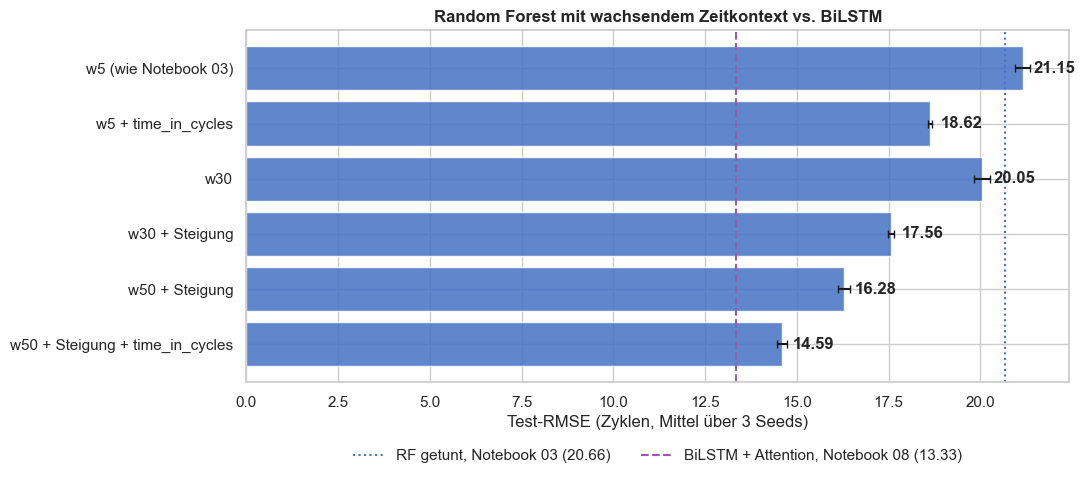

In [5]:
ref = load_results()
bilstm_rmse = ref['BiLSTM + Attention']['RMSE']
rf03_rmse   = ref['Random Forest']['RMSE']

fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(ablation))
ax.barh(y, ablation['Test-RMSE'], xerr=ablation['Test-RMSE SD'], color='#4472C4', alpha=0.85, capsize=3)
ax.axvline(rf03_rmse,   color='#4472C4', linestyle=':',  label=f'RF getunt, Notebook 03 ({rf03_rmse})')
ax.axvline(bilstm_rmse, color='#9B59B6', linestyle='--', label=f'BiLSTM + Attention, Notebook 08 ({bilstm_rmse})')
for yi, v in zip(y, ablation['Test-RMSE']):
    ax.text(v + 0.3, yi, f'{v:.2f}', va='center', fontweight='bold')
ax.set_yticks(y); ax.set_yticklabels(ablation.index); ax.invert_yaxis()
ax.set_xlabel('Test-RMSE (Zyklen, Mittel über 3 Seeds)')
ax.set_title('Random Forest mit wachsendem Zeitkontext vs. BiLSTM', fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)  # unter der Achse: verdeckt keinen Balken
plt.tight_layout()
plt.savefig(REPORTS / 'context_ablation.png', dpi=150)
plt.show()

gap_before = rf03_rmse - bilstm_rmse
gap_after  = ablation.loc[best_cv, 'Test-RMSE'] - bilstm_rmse
print(f'Abstand RF → BiLSTM: vorher {gap_before:.2f} Zyklen, mit 50-Zyklen-Kontext (CV-Auswahl) {gap_after:.2f} Zyklen '
      f'→ {1 - gap_after / gap_before:.0%} des Abstands erklärt der Kontext')

## 4. Interpretation

*(Zahlen aus dem Lauf vom 21.10.2026, Tabelle oben)*

1. **Der Zeitkontext erklärt den größten Teil des BiLSTM-Vorsprungs.** Mit 5-Zyklen-Features liegt der Random Forest bei Test-RMSE 21.15. Mit 50-Zyklen-Mittelwert, -Streuung und -Steigung plus `time_in_cycles` (Auswahl per CV) sinkt er auf 14.59 ± 0.14, nur noch 1.26 Zyklen über dem BiLSTM (13.33). Rund 83 % des ursprünglichen Abstands erklärt die Information, die das Modell sieht, nicht die Modellklasse.
2. **Der Trend zählt mehr als die Glättung.** Ein längeres Fenster allein (w30 ohne Steigung: 20.05) hilft kaum. Erst die Steigung, also wie schnell sich ein Sensor verändert, bringt den großen Sprung (w30 + Steigung: 17.56). Genau diese Information liest das BiLSTM direkt aus der Sequenz.
3. **Das Alter der Engine ist ein starkes Merkmal.** `time_in_cycles` verbessert jede Variante deutlich, beim NASA Score am stärksten (z. B. 2088 → 681 bei Fenster 5). Das BiLSTM kennt diesen Wert nicht, es sieht nur die letzten 50 Zyklen.
4. **Das BiLSTM bleibt vorn,** beim RMSE knapp (13.33 vs. 14.59) und beim NASA Score deutlich (265 vs. 495). Der Vorsprung ist aber viel kleiner, als der ursprüngliche Vergleich (13.33 vs. 20.72) nahelegt.

**Einschränkungen:** Random Forest ohne Tuning, 3 Seeds. CV und Test bewerten unterschiedliche Zeitpunkte (alle Zyklen bzw. letzter Zyklus), deshalb liegen die CV-Werte niedriger. Die BiLSTM-Zahl ist der beste von mehreren Trainingsläufen (siehe Notebook 08), der Vergleich ist also eher zugunsten des BiLSTM.